### Task 1: Crime Trend Over Years

Calculates yearly crime counts using Pandas grouping and visualizes the trend through a Matplotlib line chart, which is saved for the Flask dashboard. Interprets the recorded crime trends while acknowledging uneven yearly data coverage.

========== DATASET LOADED ==========
Total Crime Records: 498

========== CRIME COUNT PER YEAR ==========


,year,crime_count
0,2012,2
1,2013,1
2,2014,1
3,2015,4
4,2016,490


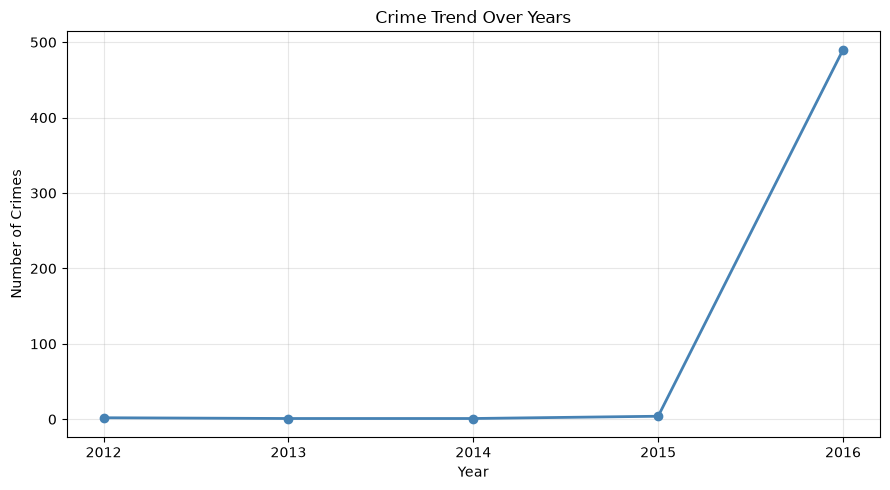


Chart Saved: crime_trend_over_years.png

========== ASSESSMENT QUESTION ==========
Question: Is the crime rate rising or decreasing?
Answer: Recorded crime counts increase from the earliest to the latest year in the supplied sample.
Interpretation: The dataset has uneven year-wise coverage, with most records belonging to 2016.
Therefore, these counts cannot establish whether Chicago's actual citywide crime rate increased or decreased.

USE CASE 2 - TASK 1: PASS


In [1]:

# ============================================================
# USE CASE 2 - CODE CELL 1
# TASK 1: CRIME TREND OVER YEARS
# ============================================================

# Assessment Requirements:
# 1. Calculate the total number of crimes per year.
# 2. Plot yearly crime counts using a line chart.
# 3. Answer whether crime is rising or decreasing.
#
# Methods Used:
# pd.read_csv() loads the cleaned dataset.
# pd.to_datetime() converts the Date column.
# groupby() groups crimes by year.
# size() counts crimes in each year.
# reset_index() converts the results into a DataFrame.
# plt.plot() creates the required line chart.
# plt.savefig() saves the chart for the Flask dashboard.
#



# ============================================================
# STEP 1: IMPORT REQUIRED LIBRARIES
# ============================================================

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display


# ============================================================
# STEP 2: LOCATE THE NEW PROJECT DIRECTORY
# ============================================================

BASE_DIR = Path.cwd().resolve()

if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent

# Ensure we are using the new project, not the old one.
assert BASE_DIR.name == "Chicago_Crime_Capstone_2026", (
    f"Incorrect project directory: {BASE_DIR}"
)


# ============================================================
# STEP 3: DEFINE DATASET AND CHART PATHS
# ============================================================

# Notebook 01 created this feature-engineered dataset.
DATA_FILE = (
    BASE_DIR / "data" / "cleaned" /
    "chicago_crime_features.csv"
)

# Charts will be used by the Flask dashboard.
CHARTS_DIR = BASE_DIR / "static" / "charts"

CHARTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

assert DATA_FILE.is_file(), (
    f"Cleaned dataset not found: {DATA_FILE}"
)


# ============================================================
# STEP 4: LOAD THE CLEANED DATASET
# ============================================================

eda_df = pd.read_csv(
    DATA_FILE,
    low_memory=False
)

# Ensure Date and Year contain the correct data types.
eda_df["date"] = pd.to_datetime(
    eda_df["date"],
    errors="coerce"
)

eda_df["year"] = pd.to_numeric(
    eda_df["year"],
    errors="coerce"
)

# Validate that cleaned records are available.
assert len(eda_df) == 498
assert eda_df.shape[1] == 22
assert eda_df["date"].notna().all()
assert eda_df["year"].notna().all()

# Check that Year matches the incident Date.
assert (
    eda_df["year"] == eda_df["date"].dt.year
).all()

print("========== DATASET LOADED ==========")
print("Total Crime Records:", len(eda_df))


# ============================================================
# STEP 5: CALCULATE CRIME COUNT PER YEAR
# ============================================================

# groupby() groups the records by year.
# size() counts the incidents within each group.
yearly_crimes = (
    eda_df.groupby("year")
    .size()
    .reset_index(name="crime_count")
    .sort_values("year")
)

print("\n========== CRIME COUNT PER YEAR ==========")

display(yearly_crimes)


# ============================================================
# STEP 6: CREATE THE REQUIRED LINE CHART
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(
    yearly_crimes["year"],
    yearly_crimes["crime_count"],
    marker="o",
    linewidth=2,
    color="steelblue"
)

plt.title("Crime Trend Over Years")
plt.xlabel("Year")
plt.ylabel("Number of Crimes")

# Show every year in the supplied dataset.
plt.xticks(yearly_crimes["year"])

plt.grid(True, alpha=0.3)
plt.tight_layout()


# ============================================================
# STEP 7: SAVE THE CHART FOR THE FLASK DASHBOARD
# ============================================================

chart_path = (
    CHARTS_DIR / "crime_trend_over_years.png"
)

plt.savefig(
    chart_path,
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("\nChart Saved:", chart_path.name)


# ============================================================
# STEP 8: ANSWER THE ASSESSMENT QUESTION
# ============================================================

print("\n========== ASSESSMENT QUESTION ==========")

print(
    "Question: Is the crime rate rising or decreasing?"
)

first_count = int(
    yearly_crimes["crime_count"].iloc[0]
)

last_count = int(
    yearly_crimes["crime_count"].iloc[-1]
)

if last_count > first_count:

    print(
        "Answer: Recorded crime counts increase "
        "from the earliest to the latest year "
        "in the supplied sample."
    )

elif last_count < first_count:

    print(
        "Answer: Recorded crime counts decrease "
        "from the earliest to the latest year "
        "in the supplied sample."
    )

else:

    print(
        "Answer: The earliest and latest years "
        "have equal recorded crime counts."
    )

# Explain the limitation accurately.
print(
    "Interpretation: The dataset has uneven year-wise "
    "coverage, with most records belonging to 2016."
)

print(
    "Therefore, these counts cannot establish "
    "whether Chicago's actual citywide crime rate "
    "increased or decreased."
)


# ============================================================
# STEP 9: VALIDATE THE RESULTS
# ============================================================

# Grouped crimes must equal the total source records.
assert yearly_crimes["crime_count"].sum() == len(eda_df)

# Every year must appear only once in the summary.
assert yearly_crimes["year"].is_unique

# Confirm that the required chart was saved.
assert chart_path.is_file()
assert chart_path.stat().st_size > 0

print("\nUSE CASE 2 - TASK 1: PASS")


### Task 2: Crime Distribution by Category

Joins crime records with the IUCR reference dataset to calculate crime category counts and percentages. Visualizes the top 10 categories using a Seaborn bar chart, identifies the most frequent crime category and saves the chart for the Flask dashboard.

========== CRIME CATEGORY DISTRIBUTION ==========


,primary_type,crime_count,percentage
0,THEFT,105,21.08
1,BATTERY,85,17.07
2,CRIMINAL DAMAGE,49,9.84
3,OTHER OFFENSE,39,7.83
4,DECEPTIVE PRACTICE,38,7.63
5,ASSAULT,35,7.03
6,NARCOTICS,32,6.43
7,ROBBERY,30,6.02
8,CRIMINAL TRESPASS,17,3.41
9,MOTOR VEHICLE THEFT,16,3.21



========== TOP 10 CRIME CATEGORIES ==========


,primary_type,crime_count,percentage
0,THEFT,105,21.08
1,BATTERY,85,17.07
2,CRIMINAL DAMAGE,49,9.84
3,OTHER OFFENSE,39,7.83
4,DECEPTIVE PRACTICE,38,7.63
5,ASSAULT,35,7.03
6,NARCOTICS,32,6.43
7,ROBBERY,30,6.02
8,CRIMINAL TRESPASS,17,3.41
9,MOTOR VEHICLE THEFT,16,3.21


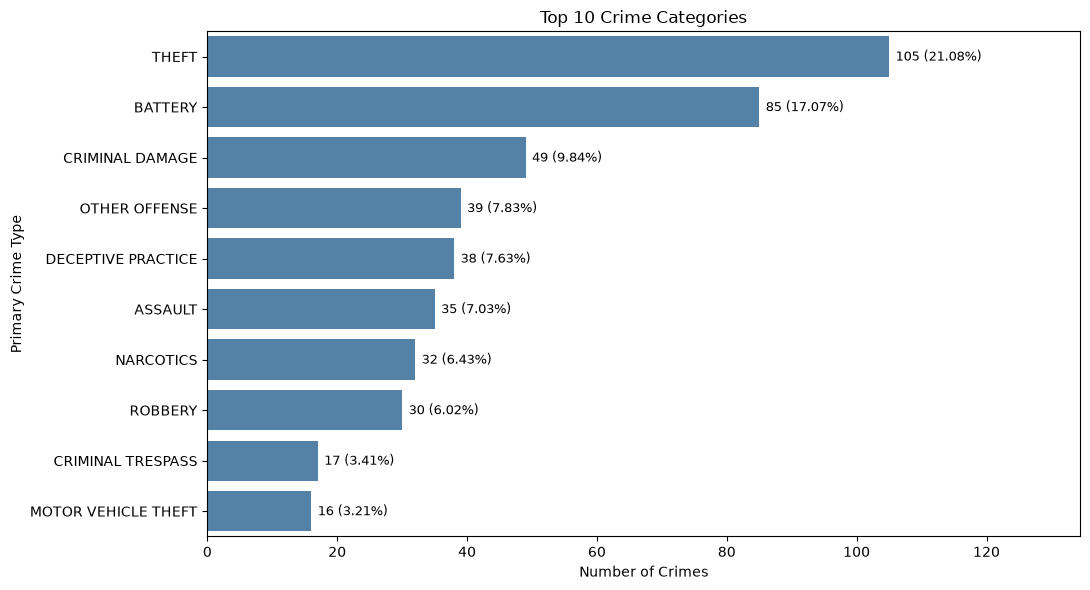


Chart Saved: top_10_crime_categories.png

========== ASSESSMENT QUESTION ==========
Question: Which crime category is most frequent?
Answer: THEFT
Crime Count: 105
Percentage: 21.08%

USE CASE 2 - TASK 2: PASS


In [2]:

# ============================================================
# USE CASE 2 - CODE CELL 2
# TASK 2: CRIME DISTRIBUTION BY CATEGORY
# ============================================================

# Assessment Requirements:
# 1. Identify crime categories using Primary Type.
# 2. Calculate crime counts for each category.
# 3. Calculate the percentage of each category.
# 4. Create a bar chart of the top 10 categories.
#
# Assessment Question:
# Which crime category is most frequent?
#
# Methods Used:
# pd.read_csv() loads the IUCR reference dataset.
# str.strip() removes extra whitespace.
# str.upper() standardizes categorical values.
# str.zfill() standardizes IUCR code lengths.
# merge() matches crime records with Primary Type.
# value_counts() calculates category frequencies.
# reset_index() creates the summary DataFrame.
# sns.barplot() creates the required bar chart.
# savefig() saves the chart for the Flask dashboard.
#
# Important:
# The master crime dataset contains IUCR codes.
# Primary Type comes from the IUCR reference dataset.
# No crime records are discarded during the join.


# ============================================================
# STEP 1: IMPORT REQUIRED LIBRARIES
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display


# ============================================================
# STEP 2: LOAD THE IUCR REFERENCE DATASET
# ============================================================

# Use the original IUCR source file.
IUCR_FILE = (
    BASE_DIR / "data" / "raw" /
    "iucr_codes.csv.csv"
)

# Support the standard CSV filename if renamed.
if not IUCR_FILE.is_file():

    IUCR_FILE = (
        BASE_DIR / "data" / "raw" /
        "iucr_codes.csv"
    )

assert IUCR_FILE.is_file(), (
    f"IUCR dataset not found: {IUCR_FILE}"
)

iucr_df = pd.read_csv(
    IUCR_FILE,
    dtype=str,
    low_memory=False
)


# ============================================================
# STEP 3: STANDARDIZE IUCR REFERENCE COLUMNS
# ============================================================

# Convert column names to lowercase and remove spaces.
# Example: "PRIMARY_TYPE " becomes "primary_type".
iucr_df.columns = (
    iucr_df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

# Match the reference key to the cleaned dataset.
iucr_df = iucr_df.rename(
    columns={
        "iucr": "iucr_code"
    }
)

# Verify the required reference columns exist.
assert {
    "iucr_code",
    "primary_type"
}.issubset(iucr_df.columns)


# ============================================================
# STEP 4: STANDARDIZE IUCR CODES
# ============================================================

# Work with a copy of crime identifiers.
# This keeps eda_df unchanged for later tasks.
crime_codes_df = eda_df[
    ["iucr_code"]
].copy()

# Convert crime IUCR codes into four-character strings.
# Example: 486 becomes 0486.
crime_codes_df["iucr_code"] = (
    crime_codes_df["iucr_code"]
    .astype("string")
    .str.strip()
    .str.upper()
    .str.zfill(4)
)

# Apply the same standardization to reference codes.
iucr_df["iucr_code"] = (
    iucr_df["iucr_code"]
    .astype("string")
    .str.strip()
    .str.upper()
    .str.zfill(4)
)

# Standardize Primary Type descriptions.
iucr_df["primary_type"] = (
    iucr_df["primary_type"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# Each IUCR reference code must be unique.
assert iucr_df["iucr_code"].is_unique


# ============================================================
# STEP 5: MATCH CRIMES WITH PRIMARY TYPE
# ============================================================

# Join crime codes with their primary crime categories.
# A left join preserves every original crime record.
crime_category_df = crime_codes_df.merge(
    iucr_df[
        ["iucr_code", "primary_type"]
    ],
    on="iucr_code",
    how="left",
    validate="many_to_one"
)

# Verify that all 498 crime records are preserved.
assert len(crime_category_df) == len(eda_df)

# Verify that all IUCR codes match a Primary Type.
assert crime_category_df["primary_type"].notna().all(), (
    "Some crime IUCR codes could not be matched."
)


# ============================================================
# STEP 6: CALCULATE CRIME COUNTS AND PERCENTAGES
# ============================================================

# value_counts() calculates frequency per Primary Type.
category_counts = (
    crime_category_df["primary_type"]
    .value_counts()
)

# Percentage = Category Count / Total Crimes * 100.
category_summary = (
    category_counts
    .rename_axis("primary_type")
    .reset_index(name="crime_count")
)

category_summary["percentage"] = (
    category_summary["crime_count"]
    / len(crime_category_df)
    * 100
).round(2)

# Display all categories with their counts and percentages.
print("========== CRIME CATEGORY DISTRIBUTION ==========")

display(category_summary)


# ============================================================
# STEP 7: SELECT TOP 10 CRIME CATEGORIES
# ============================================================

# The categories are already sorted by crime count.
top_10_categories = category_summary.head(10).copy()

print("\n========== TOP 10 CRIME CATEGORIES ==========")

display(top_10_categories)


# ============================================================
# STEP 8: CREATE THE REQUIRED BAR CHART
# ============================================================

fig, ax = plt.subplots(figsize=(11, 6))

# Horizontal bars make long category names readable.
sns.barplot(
    data=top_10_categories,
    x="crime_count",
    y="primary_type",
    color="steelblue",
    ax=ax
)

ax.set_title("Top 10 Crime Categories")
ax.set_xlabel("Number of Crimes")
ax.set_ylabel("Primary Crime Type")

# Display the count and percentage beside each bar.
for index, row in top_10_categories.iterrows():

    ax.text(
        row["crime_count"] + 1,
        index,
        f'{row["crime_count"]} ({row["percentage"]:.2f}%)',
        va="center",
        fontsize=9
    )

# Leave space for the count and percentage labels.
ax.set_xlim(
    0,
    top_10_categories["crime_count"].max() * 1.28
)

plt.tight_layout()


# ============================================================
# STEP 9: SAVE CHART FOR THE FLASK DASHBOARD
# ============================================================

chart_path = (
    CHARTS_DIR / "top_10_crime_categories.png"
)

fig.savefig(
    chart_path,
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("\nChart Saved:", chart_path.name)


# ============================================================
# STEP 10: ANSWER THE ASSESSMENT QUESTION
# ============================================================

# The first category has the highest crime count.
most_common_crime = category_summary.iloc[0]

print("\n========== ASSESSMENT QUESTION ==========")

print("Question: Which crime category is most frequent?")

print(
    "Answer:",
    most_common_crime["primary_type"]
)

print(
    "Crime Count:",
    int(most_common_crime["crime_count"])
)

print(
    "Percentage:",
    f'{most_common_crime["percentage"]:.2f}%'
)


# ============================================================
# STEP 11: VALIDATE THE RESULTS
# ============================================================

# Every crime must belong to one matched Primary Type.
assert category_summary["crime_count"].sum() == 498

# The uploaded dataset contains 23 crime categories.
assert len(category_summary) == 23

# The chart must contain exactly 10 categories.
assert len(top_10_categories) == 10

# Verify the calculated most frequent crime.
assert most_common_crime["primary_type"] == "THEFT"
assert int(most_common_crime["crime_count"]) == 105

# Check that the saved chart exists and is not empty.
assert chart_path.is_file()
assert chart_path.stat().st_size > 0

print("\nUSE CASE 2 - TASK 2: PASS")


### Task 3: Arrests and Crime Outcomes

Converts arrest indicators into numeric values and calculates the overall arrest percentage using the mean() method. Analyzes yearly arrest rates using Pandas grouping to evaluate consistency across years while acknowledging limited sample coverage.

In [3]:

# ============================================================
# USE CASE 2 - CODE CELL 3
# TASK 3: ARRESTS AND CRIME OUTCOMES
# ============================================================

# Assessment Requirements:
# 1. Calculate the percentage of crimes resulting in arrest.
# 2. Use mean() * 100 for the overall arrest rate.
# 3. Determine whether arrest rates are consistent by year.
#
# Methods Used:
# astype() and map() convert arrest values to 1 and 0.
# mean() calculates the proportion of arrests.
# sum() calculates the number of arrests.
# groupby() groups records by year.
# agg() calculates the yearly crime and arrest counts.
# round() formats percentages to two decimal places.



# ============================================================
# STEP 1: PREPARE ARREST DATA
# ============================================================

# Work with a copy so previous analysis is unchanged.
arrest_df = eda_df[["year", "arrest"]].copy()

# Convert TRUE/FALSE and 1/0 values into numeric flags.
# TRUE or 1 means an arrest was made.
# FALSE or 0 means no arrest was recorded.
arrest_df["arrest"] = (
    arrest_df["arrest"]
    .astype("string")
    .str.strip()
    .str.lower()
    .map({
        "true": 1,
        "false": 0,
        "1": 1,
        "0": 0
    })
)

# Ensure all arrest indicators are valid.
assert arrest_df["arrest"].notna().all()

# Convert Year to numeric values.
arrest_df["year"] = pd.to_numeric(
    arrest_df["year"],
    errors="coerce"
)

assert arrest_df["year"].notna().all()


# ============================================================
# STEP 2: CALCULATE THE OVERALL ARREST PERCENTAGE
# ============================================================

# Count the total crime records.
total_crimes = len(arrest_df)

# sum() counts records with an arrest indicator of 1.
total_arrests = int(arrest_df["arrest"].sum())

# mean() calculates the proportion of arrest records.
# Multiplication by 100 converts it to a percentage.
arrest_rate = arrest_df["arrest"].mean() * 100

print("========== ARREST ANALYSIS ==========")

print("Total Crimes:", total_crimes)
print("Total Arrests:", total_arrests)
print("Arrest Percentage:", f"{arrest_rate:.2f}%")


# ============================================================
# STEP 3: ANSWER THE ARREST PERCENTAGE QUESTION
# ============================================================

print("\n========== ASSESSMENT QUESTION 1 ==========")

print("Question: What percentage of crimes result in arrest?")

print(
    f"Answer: {arrest_rate:.2f}% of recorded crime "
    "incidents have an arrest flag."
)


# ============================================================
# STEP 4: CALCULATE YEARLY ARREST RATES
# ============================================================

# Group crime records by year.
# count() counts crime records for each year.
# sum() counts arrests for each year.
yearly_arrest_rates = (
    arrest_df.groupby("year")["arrest"]
    .agg(
        total_crimes="count",
        arrest_count="sum"
    )
    .reset_index()
    .sort_values("year")
)

# Calculate arrest percentage for each year.
yearly_arrest_rates["arrest_rate"] = (
    yearly_arrest_rates["arrest_count"]
    / yearly_arrest_rates["total_crimes"]
    * 100
).round(2)

# Format the year and count columns.
yearly_arrest_rates["year"] = (
    yearly_arrest_rates["year"].astype(int)
)

yearly_arrest_rates["arrest_count"] = (
    yearly_arrest_rates["arrest_count"].astype(int)
)

print("\n========== YEARLY ARREST RATES ==========")

display(yearly_arrest_rates)


# ============================================================
# STEP 5: ANSWER THE CONSISTENCY QUESTION
# ============================================================

print("\n========== ASSESSMENT QUESTION 2 ==========")

print(
    "Question: Is the arrest rate consistent "
    "across different years?"
)

# Check whether the calculated yearly rates are equal.
if yearly_arrest_rates["arrest_rate"].nunique() == 1:

    print(
        "Answer: Yes. Arrest rates are equal "
        "across the years in the sample."
    )

else:

    print(
        "Answer: No. Arrest rates are not "
        "consistent across different years."
    )

print(
    "Interpretation: The early years contain very "
    "few crime records, making their arrest "
    "percentages unstable."
)

print(
    "These sample percentages should not be "
    "interpreted as official citywide arrest rates."
)


# ============================================================
# STEP 6: VALIDATE THE RESULTS
# ============================================================

# Verify the total source crime count.
assert total_crimes == 498

# Verify the arrest count against the source dataset.
assert total_arrests == 124

# Verify the overall arrest percentage.
assert round(arrest_rate, 2) == 24.90

# Yearly totals must equal the original crime records.
assert yearly_arrest_rates["total_crimes"].sum() == total_crimes

# Yearly arrest counts must equal the overall arrests.
assert yearly_arrest_rates["arrest_count"].sum() == total_arrests

# Confirm the original DataFrame remains unchanged.
assert len(eda_df) == 498


# ============================================================
# STEP 7: COMPLETION STATUS
# ============================================================

print("\nUSE CASE 2 - TASK 3: PASS")


========== ARREST ANALYSIS ==========
Total Crimes: 498
Total Arrests: 124
Arrest Percentage: 24.90%

========== ASSESSMENT QUESTION 1 ==========
Question: What percentage of crimes result in arrest?
Answer: 24.90% of recorded crime incidents have an arrest flag.

========== YEARLY ARREST RATES ==========


,year,total_crimes,arrest_count,arrest_rate
0,2012,2,2,100.0
1,2013,1,1,100.0
2,2014,1,0,0.0
3,2015,4,2,50.0
4,2016,490,119,24.29



========== ASSESSMENT QUESTION 2 ==========
Question: Is the arrest rate consistent across different years?
Answer: No. Arrest rates are not consistent across different years.
Interpretation: The early years contain very few crime records, making their arrest percentages unstable.
These sample percentages should not be interpreted as official citywide arrest rates.

USE CASE 2 - TASK 3: PASS


### Task 4: Heatmap of Crime by Month and Day of Week

Calculates crime frequencies by month and weekday using Pandas crosstab() and visualizes them through a Seaborn heatmap in calendar order. Identifies the month with the highest crime frequency and saves the chart for the Flask dashboard.

========== MONTH-WEEKDAY CRIME FREQUENCY ==========


day_of_week,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
month,,,,,,,
1,1,1,1,2,3,0,2
2,0,1,0,1,1,1,1
3,3,4,2,1,1,1,0
4,7,3,1,1,6,2,2
5,1,146,299,0,0,0,1
6,0,0,0,0,0,0,0
7,0,0,0,0,0,0,0
8,0,0,0,0,0,0,0
9,0,0,0,0,0,0,0


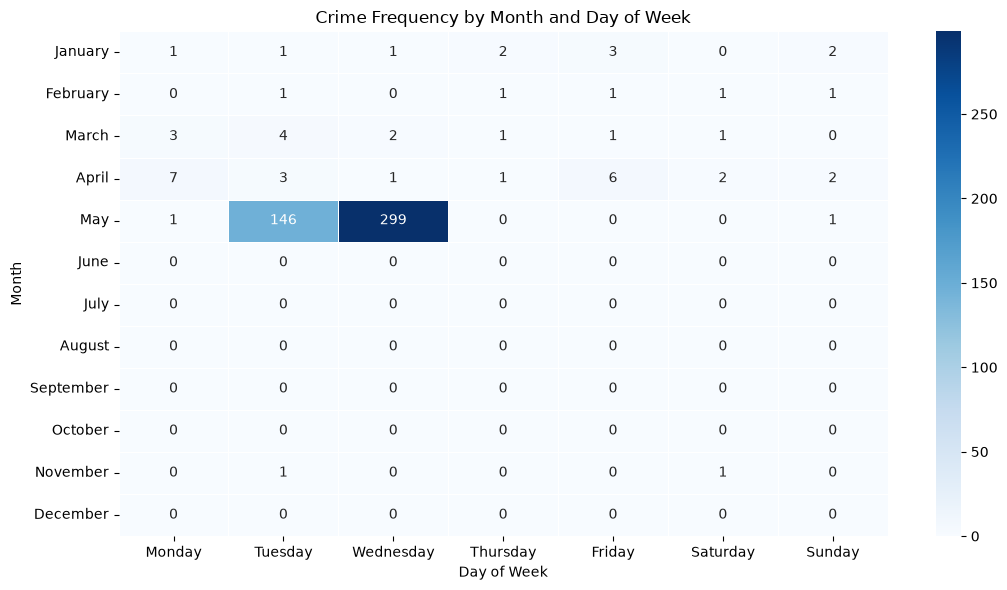


Chart Saved: crime_month_weekday_heatmap.png

========== ASSESSMENT QUESTION ==========
Question: Which month has the highest crime frequency?
Answer: May
Number of Crimes: 447
Percentage of Total Crimes: 89.76%
Interpretation: This month contains the highest number of crime records in the supplied sample.
The dataset has uneven coverage across months, so this result does not establish a citywide seasonal crime pattern.

USE CASE 2 - TASK 4: PASS


In [4]:

# ============================================================
# USE CASE 2 - CODE CELL 4
# TASK 4: HEATMAP OF CRIME BY MONTH AND DAY OF WEEK
# ============================================================

# Assessment Requirements:
# 1. Calculate crime frequency by Month and DayOfWeek.
# 2. Visualize the results using a Seaborn heatmap.
#
# Assessment Question:
# Which month has the highest crime frequency?
#
# Methods Used:
# pd.crosstab() counts crimes for each Month-Day combination.
# reindex() arranges months and weekdays correctly.
# sns.heatmap() creates the required heatmap.
# value_counts() calculates total crimes per month.
# idxmax() identifies the month with the highest count.
# savefig() saves the chart for the Flask dashboard.



# ============================================================
# STEP 1: IMPORT REQUIRED LIBRARIES
# ============================================================

import calendar
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display


# ============================================================
# STEP 2: PREPARE MONTH AND DAY OF WEEK DATA
# ============================================================

# Work with the cleaned data loaded in Code Cell 1.
heatmap_df = eda_df[
    ["month", "day_of_week"]
].copy()

# Ensure Month contains numeric values.
heatmap_df["month"] = pd.to_numeric(
    heatmap_df["month"],
    errors="coerce"
)

# Standardize weekday names.
heatmap_df["day_of_week"] = (
    heatmap_df["day_of_week"]
    .astype("string")
    .str.strip()
    .str.title()
)

# Check for missing values.
assert heatmap_df.notna().all().all(), (
    "Missing Month or DayOfWeek values detected."
)

# Define the calendar weekday order.
weekday_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]


# ============================================================
# STEP 3: CALCULATE MONTH-WEEKDAY CRIME FREQUENCY
# ============================================================

# crosstab() counts crimes for each combination.
crime_heatmap = pd.crosstab(
    heatmap_df["month"],
    heatmap_df["day_of_week"]
)

# Arrange the months from January to December.
# Arrange weekdays from Monday to Sunday.
# fill_value=0 represents combinations with no crimes.
crime_heatmap = crime_heatmap.reindex(
    index=range(1, 13),
    columns=weekday_order,
    fill_value=0
)

# Display the required frequency matrix.
print("========== MONTH-WEEKDAY CRIME FREQUENCY ==========")

display(crime_heatmap)


# ============================================================
# STEP 4: CREATE THE REQUIRED SEABORN HEATMAP
# ============================================================

fig, ax = plt.subplots(figsize=(11, 6))

sns.heatmap(
    crime_heatmap,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=0.5,
    ax=ax
)

ax.set_title("Crime Frequency by Month and Day of Week")
ax.set_xlabel("Day of Week")
ax.set_ylabel("Month")

# Show readable month names in calendar order.
ax.set_yticklabels(
    list(calendar.month_name)[1:],
    rotation=0
)

plt.tight_layout()


# ============================================================
# STEP 5: SAVE THE CHART FOR THE FLASK DASHBOARD
# ============================================================

chart_path = (
    CHARTS_DIR / "crime_month_weekday_heatmap.png"
)

fig.savefig(
    chart_path,
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("\nChart Saved:", chart_path.name)


# ============================================================
# STEP 6: CALCULATE TOTAL CRIMES PER MONTH
# ============================================================

# Count the number of crime records for each month.
monthly_counts = (
    heatmap_df["month"]
    .value_counts()
    .sort_index()
    .reindex(range(1, 13), fill_value=0)
)

# Identify the month with the largest number of crimes.
highest_month_number = int(
    monthly_counts.idxmax()
)

highest_month_name = calendar.month_name[
    highest_month_number
]

highest_month_count = int(
    monthly_counts.max()
)

# Calculate its percentage of all crime records.
highest_month_percentage = (
    highest_month_count / len(heatmap_df) * 100
)


# ============================================================
# STEP 7: ANSWER THE ASSESSMENT QUESTION
# ============================================================

print("\n========== ASSESSMENT QUESTION ==========")

print(
    "Question: Which month has the highest "
    "crime frequency?"
)

print("Answer:", highest_month_name)

print("Number of Crimes:", highest_month_count)

print(
    "Percentage of Total Crimes:",
    f"{highest_month_percentage:.2f}%"
)

# Explain what the result means.
print(
    "Interpretation: This month contains the highest "
    "number of crime records in the supplied sample."
)

print(
    "The dataset has uneven coverage across months, "
    "so this result does not establish a citywide "
    "seasonal crime pattern."
)


# ============================================================
# STEP 8: VALIDATE THE RESULTS
# ============================================================

# Every crime must be represented in the frequency matrix.
assert crime_heatmap.to_numpy().sum() == len(eda_df)

# The monthly totals must equal the heatmap row totals.
assert (
    crime_heatmap.sum(axis=1).to_numpy()
    ==
    monthly_counts.to_numpy()
).all()

# The calendar matrix must contain 12 months and 7 days.
assert crime_heatmap.shape == (12, 7)

# Confirm the source crime count.
assert len(eda_df) == 498

# Confirm the chart was created successfully.
assert chart_path.is_file()
assert chart_path.stat().st_size > 0

print("\nUSE CASE 2 - TASK 4: PASS")


### Task 5: Top 10 Community Areas

Joins crime records with the community reference dataset to calculate crime counts and identify the top 10 community areas. Visualizes the results using a Seaborn bar chart, identifies the community with the highest recorded crime count and saves the chart for the Flask dashboard.

========== TOP 10 COMMUNITY AREAS ==========


,community_name,crime_count
0,Austin,34
1,Near North Side,20
2,Humboldt Park,20
3,South Shore,16
4,Englewood,16
5,South Lawndale,16
6,Loop,15
7,Auburn Gresham,14
8,Lake View,14
9,Roseland,14


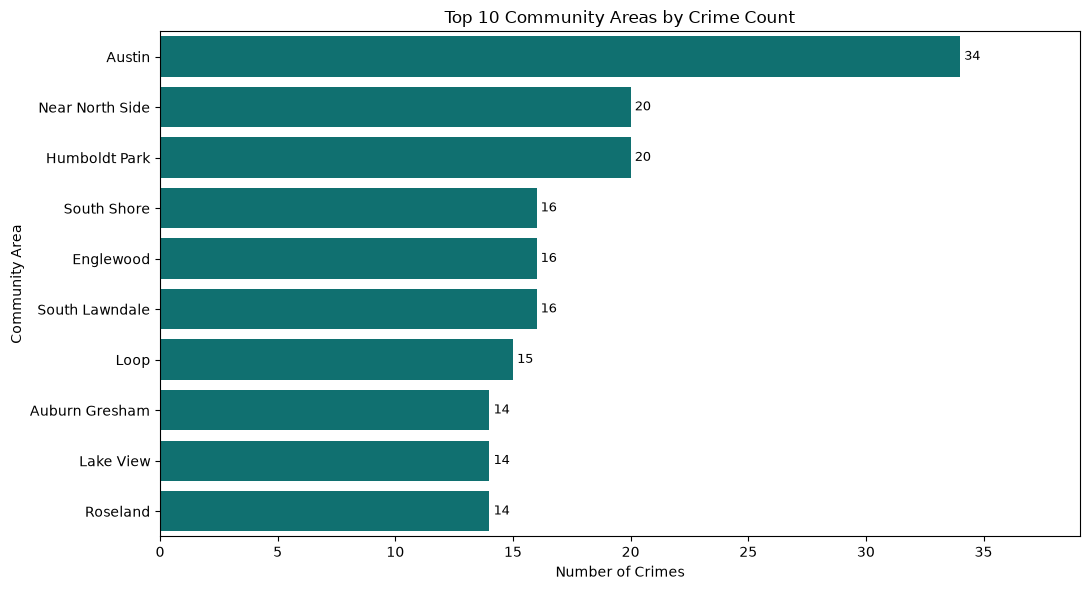


Chart Saved: top10_communities.png

========== COMMUNITY AREA INSIGHT ==========
Community With Highest Crime Count: Austin
Crime Count: 34
Percentage of Total Crimes: 6.83%
Interpretation: This community area has the highest recorded crime count in the supplied dataset.
Note: The supplied sample does not establish the actual citywide crime rate for each area.

========== USE CASE 2 SUMMARY ==========
Task 1: Crime Trend Over Years
Task 2: Crime Distribution by Category
Task 3: Arrests and Crime Outcomes
Task 4: Month and Day of Week Heatmap
Task 5: Top 10 Community Areas

USE CASE 2 - TASK 5: PASS
USE CASE 2: PASS


In [5]:

# ============================================================
# USE CASE 2 - CODE CELL 5
# TASK 5: TOP 10 COMMUNITY AREAS
# ============================================================

# Assessment Requirements:
# 1. Identify the 10 community areas with the
#    highest number of recorded crimes.
# 2. List the community names and crime counts.
# 3. Plot the results using a bar chart.
#
# Methods Used:
# pd.read_csv() loads the community reference dataset.
# pd.to_numeric() standardizes community identifiers.
# merge() matches crime records with community names.
# value_counts() calculates crimes per community.
# head(10) selects the top 10 community areas.
# sns.barplot() creates the required bar chart.
# savefig() saves the chart for the Flask dashboard.
#
# Important:
# No original crime records are removed or modified.
# Community names come from the supplied reference CSV.


# ============================================================
# STEP 1: IMPORT REQUIRED LIBRARIES
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display


# ============================================================
# STEP 2: LOAD THE COMMUNITY REFERENCE DATASET
# ============================================================

COMMUNITY_FILE = (
    BASE_DIR / "data" / "raw" /
    "chicago_city_community.csv"
)

assert COMMUNITY_FILE.is_file(), (
    f"Community dataset not found: {COMMUNITY_FILE}"
)

community_reference = pd.read_csv(
    COMMUNITY_FILE,
    low_memory=False
)

# Standardize reference column names.
community_reference.columns = (
    community_reference.columns
    .str.strip()
    .str.lower()
)

# Verify that the required columns exist.
assert {
    "community_code",
    "community_name"
}.issubset(community_reference.columns)


# ============================================================
# STEP 3: STANDARDIZE COMMUNITY IDENTIFIERS
# ============================================================

# Work with a copy of the crime community codes.
# This keeps eda_df unchanged for later analysis.
crime_community_df = eda_df[
    ["community_code"]
].copy()

# Convert crime community codes into numeric values.
crime_community_df["community_code"] = pd.to_numeric(
    crime_community_df["community_code"],
    errors="coerce"
)

# Convert reference community codes into numeric values.
community_reference["community_code"] = pd.to_numeric(
    community_reference["community_code"],
    errors="coerce"
)

# Remove unnecessary whitespace from community names.
community_reference["community_name"] = (
    community_reference["community_name"]
    .astype("string")
    .str.strip()
)

# Confirm that reference community codes are unique.
assert community_reference["community_code"].is_unique

# Confirm that crime community identifiers are present.
assert crime_community_df["community_code"].notna().all()


# ============================================================
# STEP 4: MATCH CRIMES WITH COMMUNITY NAMES
# ============================================================

# Merge each crime record with its community name.
# how="left" preserves all original crime records.
community_crimes = crime_community_df.merge(
    community_reference[
        ["community_code", "community_name"]
    ],
    on="community_code",
    how="left",
    validate="many_to_one"
)

# Verify that all crime records are preserved.
assert len(community_crimes) == len(eda_df)

# Verify that all crime community codes were matched.
assert community_crimes["community_name"].notna().all(), (
    "Some community codes could not be matched."
)


# ============================================================
# STEP 5: CALCULATE CRIMES PER COMMUNITY AREA
# ============================================================

# value_counts() calculates how many crime records
# belong to each community area.
community_counts = (
    community_crimes["community_name"]
    .value_counts()
    .rename_axis("community_name")
    .reset_index(name="crime_count")
)

# Select the 10 areas with the highest crime counts.
top_10_communities = (
    community_counts.head(10).copy()
)

print("========== TOP 10 COMMUNITY AREAS ==========")

display(top_10_communities)


# ============================================================
# STEP 6: CREATE THE REQUIRED BAR CHART
# ============================================================

fig, ax = plt.subplots(figsize=(11, 6))

# Use horizontal bars so community names are readable.
sns.barplot(
    data=top_10_communities,
    x="crime_count",
    y="community_name",
    order=top_10_communities["community_name"],
    color="teal",
    ax=ax
)

ax.set_title("Top 10 Community Areas by Crime Count")
ax.set_xlabel("Number of Crimes")
ax.set_ylabel("Community Area")

# Display crime counts beside the bars.
for container in ax.containers:
    ax.bar_label(
        container,
        padding=3,
        fontsize=9
    )

ax.set_xlim(
    0,
    top_10_communities["crime_count"].max() * 1.15
)

plt.tight_layout()


# ============================================================
# STEP 7: SAVE CHART FOR THE FLASK DASHBOARD
# ============================================================

chart_path = (
    CHARTS_DIR / "top10_communities.png"
)

fig.savefig(
    chart_path,
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("\nChart Saved:", chart_path.name)


# ============================================================
# STEP 8: DISPLAY THE MAIN INSIGHT
# ============================================================

# Identify the community with the highest crime count.
highest_community = top_10_communities.iloc[0]

highest_community_percentage = (
    highest_community["crime_count"]
    / len(eda_df)
    * 100
)

print("\n========== COMMUNITY AREA INSIGHT ==========")

print(
    "Community With Highest Crime Count:",
    highest_community["community_name"]
)

print(
    "Crime Count:",
    int(highest_community["crime_count"])
)

print(
    "Percentage of Total Crimes:",
    f"{highest_community_percentage:.2f}%"
)

print(
    "Interpretation: This community area has "
    "the highest recorded crime count in the "
    "supplied dataset."
)

print(
    "Note: The supplied sample does not establish "
    "the actual citywide crime rate for each area."
)


# ============================================================
# STEP 9: VALIDATE THE RESULTS
# ============================================================

# Every crime must belong to one matched community.
assert community_counts["crime_count"].sum() == len(eda_df)

# The bar chart must represent exactly 10 communities.
assert len(top_10_communities) == 10

# Verify community counts are in descending order.
assert top_10_communities[
    "crime_count"
].is_monotonic_decreasing

# Validate the highest community against source data.
assert highest_community["community_name"] == "Austin"
assert int(highest_community["crime_count"]) == 34

# Confirm that all source crime records are preserved.
assert len(eda_df) == 498

# Verify that the chart was saved.
assert chart_path.is_file()
assert chart_path.stat().st_size > 0


# ============================================================
# STEP 10: FINAL USE CASE 2 SUMMARY
# ============================================================

print("\n========== USE CASE 2 SUMMARY ==========")

print("Task 1: Crime Trend Over Years")
print("Task 2: Crime Distribution by Category")
print("Task 3: Arrests and Crime Outcomes")
print("Task 4: Month and Day of Week Heatmap")
print("Task 5: Top 10 Community Areas")

print("\nUSE CASE 2 - TASK 5: PASS")
print("USE CASE 2: PASS")


### Assessment Questions and Answers

Summarizes the most frequent crime category, yearly arrest rate consistency and the month with the highest crime frequency using the results from the previous analytical tasks.

In [6]:
# ============================================================
# USE CASE 2 - CODE CELL 6
# ASSESSMENT QUESTIONS AND ANSWERS
# ============================================================

# QUESTION 1: Which crime category is most frequent?

# Select the category with the highest crime count.
most_frequent_category = top_10_categories.iloc[0]

print("========== ASSESSMENT QUESTIONS AND ANSWERS ==========")

print("\n1. Which crime category is most frequent?")

print(
    "Most Frequent Crime Category:",
    most_frequent_category["primary_type"]
)

print(
    "Crime Count:",
    int(most_frequent_category["crime_count"])
)

print(
    "Percentage:",
    f"{most_frequent_category['crime_count'] / len(eda_df) * 100:.2f}%"
)


# QUESTION 2: Is the arrest rate consistent across years?

# Convert arrest indicators into numeric values.
arrest_flags = (
    eda_df["arrest"]
    .astype(str)
    .str.strip()
    .str.upper()
    .map({"TRUE": 1, "FALSE": 0, "1": 1, "0": 0})
)

assert arrest_flags.notna().all()

# Calculate arrest percentages grouped by year.
yearly_rates = (
    arrest_flags.groupby(eda_df["year"]).mean() * 100
)

print("\n2. Is the arrest rate consistent across different years?")

for year, rate in yearly_rates.items():
    print(f"{year}: {rate:.2f}%")

print(
    "Answer: The arrest rate is not consistent across years."
)

print(
    "Note: Uneven yearly sample sizes limit reliable comparisons."
)


# QUESTION 3: Which month has the highest crime frequency?

# Count crime records by month and identify the highest count.
import calendar

monthly_counts = eda_df["month"].value_counts()

highest_month = int(monthly_counts.idxmax())
highest_month_count = int(monthly_counts.max())

print("\n3. Which month has the highest crime frequency?")

print("Month:", calendar.month_name[highest_month])
print("Crime Count:", highest_month_count)


# ============================================================
# VALIDATE THE RESULTS
# ============================================================

assert len(eda_df) == 498
assert monthly_counts.sum() == 498
assert most_frequent_category["primary_type"] == "THEFT"
assert int(most_frequent_category["crime_count"]) == 105

print("\nUSE CASE 2 - ASSESSMENT QUESTIONS: PASS")
print("USE CASE 2: ANALYSIS COMPLETE")

========== ASSESSMENT QUESTIONS AND ANSWERS ==========

1. Which crime category is most frequent?
Most Frequent Crime Category: THEFT
Crime Count: 105
Percentage: 21.08%

2. Is the arrest rate consistent across different years?
2012: 100.00%
2013: 100.00%
2014: 0.00%
2015: 50.00%
2016: 24.29%
Answer: The arrest rate is not consistent across years.
Note: Uneven yearly sample sizes limit reliable comparisons.

3. Which month has the highest crime frequency?
Month: May
Crime Count: 447

USE CASE 2 - ASSESSMENT QUESTIONS: PASS
USE CASE 2: ANALYSIS COMPLETE
